In [47]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
room_occupancy_estimation = fetch_ucirepo(id=864) 
  
# data (as pandas dataframes) 
X = room_occupancy_estimation.data.features 
y = room_occupancy_estimation.data.targets 

# metadata 
print(room_occupancy_estimation.metadata) 
  
# variable information 
print(room_occupancy_estimation.variables) 

{'uci_id': 864, 'name': 'Room Occupancy Estimation', 'repository_url': 'https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation', 'data_url': 'https://archive.ics.uci.edu/static/public/864/data.csv', 'abstract': 'Data set for estimating the precise number of occupants in a room using multiple non-intrusive environmental sensors like temperature, light, sound, CO2 and PIR.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 10129, 'num_features': 18, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Room_Occupancy_Count'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Wed Aug 16 2023', 'dataset_doi': '10.24432/C5P605', 'creators': ['Adarsh Pal Singh', 'Sachin Chaudhari'], 'intro_paper': {'ID': 275, 'type': 'NATIVE', 'title': 'Machine Learning-Based Occupancy Estimation Using Multivariate Sensor Nodes', 'auth

Data Preprocessing

Data Cleaning, Normalization, Feature Engineering

- I don't believe there's any cleaning to do, we're not doing any clustering so I doubt that anything needs to be normalized.
- We do have many features, so possibly collapsing some of the dimensions could be helpful. But how do we decide what gets collapsed and what stays? 

Building the Linear Regression Model
We can try with varying numbers of features.

First set up the data:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler


# changing date and time to something a bit more managable
X['Hour'] = pd.to_datetime(X['Time'], format='%H:%M:%S').dt.hour
X = X.drop(columns=['Date', 'Time'])
scaler = StandardScaler()
LRModel = LinearRegression()
log = {}

Model including all features:

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify= y,test_size=0.2, random_state=42
)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [51]:
LRModel.fit(X_train, y_train)

predictions = LRModel.predict(X_test)
print('Intercept (β0):', LRModel.intercept_)
print('Coefficients (β_i):', LRModel.coef_)
print('R-squared:', r2_score(y_test, predictions))

log['full'] = r2_score(y_test, predictions)


Intercept (β0): [0.3986178]
Coefficients (β_i): [[ 0.03479702  0.0682706   0.37703555 -0.256964    0.28217875  0.06313977
   0.14405018 -0.08258583  0.02629904  0.04868131 -0.03003985 -0.03545055
  -0.00344774  0.21494867  0.05262027  0.11330519 -0.02339182]]
R-squared: 0.9084299779349083


Now compared to other models:

In [52]:
# time

X_time = X[['Hour']]
X_time_train, X_time_test, y_time_train, y_time_test = train_test_split(
    X_time, y, stratify=y,test_size=0.2, random_state=42)

LRModel_time = LRModel.fit(X_time_train, y_time_train)
predictions = LRModel_time.predict(X_time_test)

log['Time'] = r2_score(y_time_test, predictions)

# temperature

X_temperature = X[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']]
X_temperature_train, X_temperature_test, y_temperature_train, y_temperature_test = train_test_split(
    X_temperature, y,stratify=y, test_size=0.2, random_state=42)

LRModel_temperature = LRModel.fit(X_temperature_train, y_temperature_train)
predictions = LRModel_temperature.predict(X_temperature_test)

log['Temperature'] = r2_score(y_temperature_test, predictions)

# light

X_light = X[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']]
X_light_train, X_light_test, y_light_train, y_light_test = train_test_split(
    X_light, y, stratify=y, test_size=0.2, random_state=42)

LRModel_light = LRModel.fit(X_light_train, y_light_train)
predictions = LRModel_light.predict(X_light_test)

log['Light'] = r2_score(y_light_test, predictions)

# sound

X_sound = X[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']]
X_sound_train, X_sound_test, y_sound_train, y_sound_test = train_test_split(
    X_sound, y, stratify=y, test_size=0.2, random_state=42)

LRModel_sound = LRModel.fit(X_sound_train, y_sound_train)
predictions = LRModel_sound.predict(X_sound_test)

log['Sound'] = r2_score(y_sound_test, predictions)

# CO2

X_co2 = X[['S5_CO2', 'S5_CO2_Slope']]
X_co2_train, X_co2_test, y_co2_train, y_co2_test = train_test_split(
    X_co2, y, stratify=y, test_size=0.2, random_state=42)

LRModel_co2 = LRModel.fit(X_co2_train, y_co2_train)
predictions = LRModel_co2.predict(X_co2_test)

log['CO2'] = r2_score(y_co2_test, predictions)

# PIR

X_pir = X[['S6_PIR', 'S7_PIR']]
X_pir_train, X_pir_test, y_pir_train, y_pir_test = train_test_split(
    X_pir, y, stratify=y, test_size=0.2, random_state=42)

LRModel_pir = LRModel.fit(X_pir_train, y_pir_train)
predictions = LRModel_pir.predict(X_pir_test)

log['PIR'] = r2_score(y_pir_test, predictions)

# print results
print(f"{'Model':<20}{'R²':>8}")
print("-" * 28)
for title, r2 in log.items():
    print(f"{title:<20}{r2:>8.3f}")

Model                     R²
----------------------------
full                   0.908
Time                   0.077
Temperature            0.563
Light                  0.805
Sound                  0.432
CO2                    0.764
PIR                    0.556


Multinomial logistic regression Model

In [53]:
logisticModel = LogisticRegression(max_iter=1000)

logisticModel.fit(X_train, np.ravel(y_train))


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [54]:
from sklearn.metrics import accuracy_score, classification_report

y_test_1d = np.ravel(y_test)
log_predictions = logisticModel.predict(X_test)

log_accuracy = accuracy_score(y_test_1d, log_predictions)
baseline_accuracy = (y_test_1d == 0).mean()

print(f"Logistic accuracy:   {log_accuracy:.3f}")
print(f"Baseline (always 0): {baseline_accuracy:.3f}")
print()
print(classification_report(y_test_1d, log_predictions))

Logistic accuracy:   0.995
Baseline (always 0): 0.812

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1646
           1       1.00      1.00      1.00        92
           2       0.95      0.99      0.97       149
           3       0.99      0.93      0.96       139

    accuracy                           0.99      2026
   macro avg       0.98      0.98      0.98      2026
weighted avg       0.99      0.99      0.99      2026



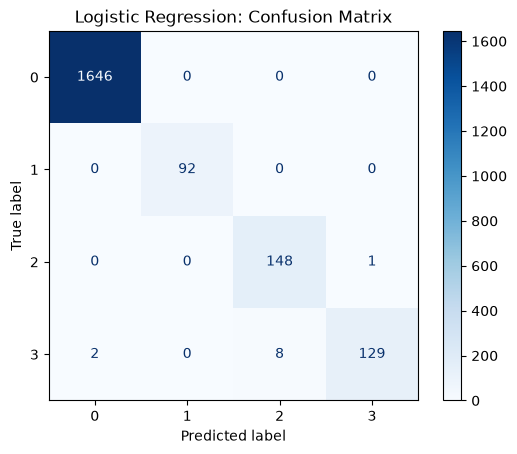

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test_1d, log_predictions, cmap='Blues')
plt.title('Logistic Regression: Confusion Matrix')
plt.show()